# 02. Modelos de probabilidad de mora (Credit Risk Analysis)

**Objetivo.** Estimar la probabilidad de que un cliente presente mora grave en los próximos dos años
(`SeriousDlqin2yrs = 1`) y comparar una regresión logística con un Random Forest.

**Protocolo para evitar fuga de información**

| Paso | Datos usados |
|---|---|
| Limpieza determinista fila a fila (`src/limpieza.py`) | cada fila por separado (sin estadísticos globales) |
| Imputación, `log1p`, escalado | ajustados dentro del pipeline, solo con entrenamiento |
| Comparación de imputación, selección de modelo y umbral | validación cruzada estratificada de 5 pliegues **dentro del entrenamiento** |
| Métricas finales, curvas, importancia por permutación | conjunto de prueba (20 %), usado una única vez |

El código reutilizable está en `src/entrenamiento.py`; este notebook ejecuta el mismo flujo paso a paso.
`python -m src.entrenamiento` reproduce los mismos artefactos sin abrir Jupyter.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
                             precision_recall_curve)

from src.cargar_datos import OBJETIVO, cargar_datos
from src.entrenamiento import (NOMBRES_MODELOS, SEMILLA, asignar_nivel_riesgo, auc_por_pliegue,
                               comparar_imputacion, construir_modelos, definir_niveles_riesgo,
                               dividir_datos, evaluar, guardar_artefactos, preparar_datos,
                               probabilidades_validacion_cruzada, seleccionar_umbral, tabla_metricas)
from src.graficos import (AZUL, AZUL_CLARO, NARANJA, TINTA, TINTA_SECUNDARIA, aplicar_estilo,
                          guardar_figura)
import src.generar_dashboard as generar_dashboard

aplicar_estilo()
pd.set_option("display.float_format", "{:,.4f}".format)

## 1. Preparación de los datos

In [2]:
df = cargar_datos()
X, y, registro = preparar_datos(df)
X_train, X_test, y_train, y_test = dividir_datos(X, y)

print("Predictoras:", list(X.columns))
print(f"Entrenamiento: {X_train.shape}  | tasa de mora {y_train.mean():.4%}")
print(f"Prueba:        {X_test.shape}  | tasa de mora {y_test.mean():.4%}")
assert OBJETIVO not in X.columns and "id_cliente" not in X.columns
assert set(X_train.index).isdisjoint(X_test.index)

Predictoras: ['RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents', 'ingreso_faltante', 'dependientes_faltante', 'codigo_especial_atraso', 'utilizacion_extrema']
Entrenamiento: (120000, 14)  | tasa de mora 6.6842%
Prueba:        (30000, 14)  | tasa de mora 6.6833%


* `y = SeriousDlqin2yrs`; la variable objetivo no está entre los predictores.
* El identificador (`id_cliente`) es el índice del DataFrame y **no** se usa como predictor: es un número
  de fila sin significado de negocio.
* No se excluye ninguna variable original. Se añaden cuatro indicadores binarios creados por la limpieza:
  `ingreso_faltante`, `dependientes_faltante`, `codigo_especial_atraso` y `utilizacion_extrema`.
* La división estratificada mantiene la misma tasa de mora (≈6,68 %) en entrenamiento y prueba.

## 2. Estrategia de imputación (validación cruzada en entrenamiento)

In [3]:
comparacion = comparar_imputacion(X_train, y_train)
comparacion.pivot(index="modelo", columns="estrategia", values="roc_auc_cv")

estrategia,mediana + indicadores,solo mediana
modelo,,
Random Forest,0.8637,0.8629
Regresión logística,0.8528,0.8506


**Resultado.** Con validación cruzada de 5 pliegues en entrenamiento, añadir los indicadores de ausencia y
de valores especiales a la imputación por mediana mejora el ROC-AUC de la regresión logística de 0,8506 a
0,8528 y el del Random Forest (100 árboles en esta comparación) de 0,8629 a 0,8637. La mejora es pequeña
pero consistente en ambos modelos y no tiene coste de interpretación, así que se adopta
**mediana + indicadores**. Era esperable: la ausencia de ingreso y los códigos 96/98 se asocian con la mora
(sección 4 y 7 del EDA) y una imputación sola borraría esa información.

## 3. Modelos y validación cruzada

| Modelo | Configuración |
|---|---|
| Referencia | `DummyClassifier(strategy="most_frequent")`: siempre predice "sin mora" |
| Regresión logística | mediana → `log1p` → `StandardScaler` → `LogisticRegression(max_iter=2000)` |
| Regresión logística balanceada | igual, con `class_weight="balanced"` |
| Random Forest | mediana → `RandomForestClassifier(n_estimators=300, min_samples_leaf=50, max_features="sqrt")` |
| Random Forest balanceado | igual, con `class_weight="balanced_subsample"` |

`min_samples_leaf=50` evita hojas con muy pocos clientes y suaviza las probabilidades. No se hizo una
búsqueda de hiperparámetros extensa: el objetivo es comparar familias de modelos con configuraciones
razonables, siempre dentro del entrenamiento.

In [4]:
modelos = construir_modelos()
proba_oof = probabilidades_validacion_cruzada(modelos, X_train, y_train)
auc_cv = pd.DataFrame({NOMBRES_MODELOS[n]: auc_por_pliegue(y_train, p) for n, p in proba_oof.items()}).T
auc_cv.columns = [f"pliegue_{i + 1}" for i in auc_cv.columns]
auc_cv["media"] = auc_cv.mean(axis=1)
auc_cv["desv_est"] = auc_cv.iloc[:, :5].std(axis=1)
auc_cv

,pliegue_1,pliegue_2,pliegue_3,pliegue_4,pliegue_5,media,desv_est
Referencia (clase mayoritaria),0.5000,0.5000,0.5000,0.5000,0.5000,0.5000,0.0000
Regresión logística,0.8573,0.8464,0.8500,0.8524,0.8580,0.8528,0.0049
Regresión logística (class_weight=balanced),0.8590,0.8483,0.8512,0.8541,0.8599,0.8545,0.0050
Random Forest,0.8685,0.8642,0.8620,0.8611,0.8658,0.8643,0.0030
Random Forest (class_weight=balanced_subsample),0.8675,0.8628,0.8608,0.8608,0.8653,0.8634,0.0029


## 4. Selección del umbral de clasificación

El umbral 0,5 no es adecuado por defecto: con un 6,68 % de positivos, un modelo bien calibrado casi
nunca asigna probabilidades superiores a 0,5 y dejaría pasar a la mayoría de los morosos.

**Criterio elegido:** maximizar **F2** sobre las probabilidades *out-of-fold* del entrenamiento. F2
pondera el recall el doble que la precision, porque en este contexto **no detectar a un cliente que caerá
en mora (falso negativo) suele costar más** que revisar a un cliente que finalmente paga (falsa alarma).
Si el área de riesgo dispusiera de costes reales por error, el umbral debería recalcularse minimizando
el coste esperado.

In [5]:
umbrales = {n: (0.5 if n == "baseline" else seleccionar_umbral(y_train, p)) for n, p in proba_oof.items()}
metricas_cv = {n: evaluar(y_train, p, umbrales[n]) for n, p in proba_oof.items()}
for nombre, p in proba_oof.items():
    metricas_cv[nombre]["roc_auc_pliegues"] = auc_por_pliegue(y_train, p)
tabla_metricas(metricas_cv).drop(columns="roc_auc_pliegues")

,umbral,roc_auc,average_precision,recall,precision,f1,f2,accuracy,tn,fp,fn,tp
modelo,,,,,,,,,,,,
Referencia (clase mayoritaria),0.5000,0.5000,0.0668,0.0000,0.0000,0.0000,0.0000,0.9332,111979,0,8021,0
Regresión logística,0.0836,0.8528,0.3806,0.6825,0.2470,0.3627,0.5045,0.8397,95287,16692,2547,5474
Regresión logística (class_weight=balanced),0.5596,0.8545,0.3824,0.6761,0.2533,0.3685,0.5069,0.8451,95992,15987,2598,5423
Random Forest,0.1077,0.8643,0.3943,0.6877,0.2723,0.3901,0.5269,0.8563,97235,14744,2505,5516
Random Forest (class_weight=balanced_subsample),0.5369,0.8634,0.3876,0.7032,0.2596,0.3792,0.5241,0.8461,95894,16085,2381,5640


                     umbral  recall  precision     f1     f2  accuracy
0,5 (por defecto)    0.5000  0.1040     0.6285 0.1784 0.1248    0.9360
máximo F1            0.2167  0.4911     0.4030 0.4427 0.4705    0.9174
máximo F2 (elegido)  0.1077  0.6877     0.2723 0.3901 0.5269    0.8563


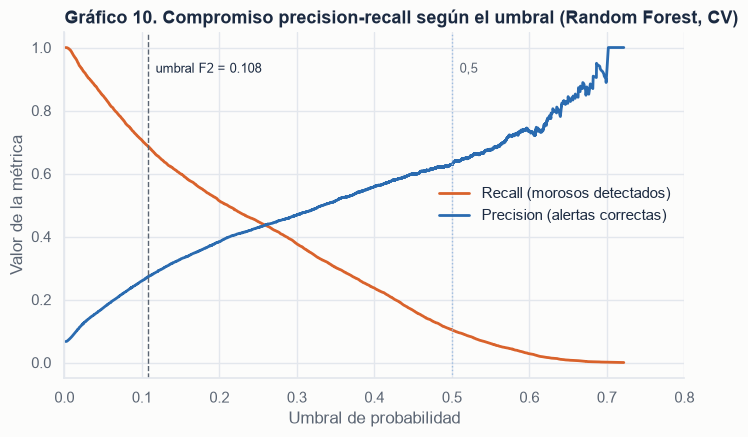

In [6]:
# Efecto del umbral para el Random Forest (predicciones out-of-fold del entrenamiento)
p_rf = proba_oof["random_forest"]
umbral_f1 = seleccionar_umbral(y_train, p_rf, beta=1)
comparacion_umbral = pd.DataFrame({
    "0,5 (por defecto)": evaluar(y_train, p_rf, 0.5),
    "máximo F1": evaluar(y_train, p_rf, umbral_f1),
    "máximo F2 (elegido)": evaluar(y_train, p_rf, umbrales["random_forest"]),
}).T[["umbral", "recall", "precision", "f1", "f2", "accuracy"]]
print(comparacion_umbral.astype(float).round(4))

precision, recall, cortes = precision_recall_curve(y_train, p_rf)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(cortes, recall[:-1], color=NARANJA, linewidth=2, label="Recall (morosos detectados)")
ax.plot(cortes, precision[:-1], color=AZUL, linewidth=2, label="Precision (alertas correctas)")
ax.axvline(umbrales["random_forest"], color=TINTA_SECUNDARIA, linestyle="--", linewidth=1)
ax.text(umbrales["random_forest"] + 0.01, 0.92, f"umbral F2 = {umbrales['random_forest']:.3f}",
        color=TINTA, fontsize=9)
ax.axvline(0.5, color=AZUL_CLARO, linestyle=":", linewidth=1)
ax.text(0.51, 0.92, "0,5", color=TINTA_SECUNDARIA, fontsize=9)
ax.set_xlim(0, 0.8)
ax.set_xlabel("Umbral de probabilidad")
ax.set_ylabel("Valor de la métrica")
ax.legend(loc="center right")
ax.set_title("Gráfico 10. Compromiso precision-recall según el umbral (Random Forest, CV)")
guardar_figura(fig, "10_umbral_precision_recall")
plt.show()

**Interpretación.** Con el umbral 0,5 el Random Forest solo detectaría el 10,4 % de los morosos del
entrenamiento (precision 62,9 %), aunque su accuracy (93,6 %) parece excelente. El umbral que maximiza F2,
**0,1077**, detecta el 68,8 % de los morosos a cambio de una precision de 27,2 %: aproximadamente 1 de
cada 4 alertas corresponde a un cliente que efectivamente cae en mora, frente al 6,7 % de una revisión
al azar. El umbral de máximo F1 (0,2167) sería un punto intermedio (recall 49,1 %, precision 40,3 %) si el
área de riesgo tuviera poca capacidad para revisar alertas.

Los modelos con `class_weight` obtienen umbrales cercanos a 0,5 porque la ponderación infla las
probabilidades; tras ajustar el umbral, su recall y precision son muy parecidos a los de los modelos sin
ponderación. Es decir, la ponderación de clases **no aporta una ventaja clara** aquí: el ajuste de umbral
cumple la misma función y conserva probabilidades interpretables.

## 5. Selección del modelo

In [7]:
candidatos = {n: m["roc_auc"] for n, m in metricas_cv.items() if n != "baseline"}
seleccionado = max(candidatos, key=candidatos.get)
umbral = umbrales[seleccionado]
print("ROC-AUC de validación cruzada:")
for n, v in sorted(candidatos.items(), key=lambda kv: -kv[1]):
    print(f"  {NOMBRES_MODELOS[n]:50s} {v:.4f}")
print(f"\nModelo seleccionado: {NOMBRES_MODELOS[seleccionado]} | umbral = {umbral:.4f}")

ROC-AUC de validación cruzada:
  Random Forest                                      0.8643
  Random Forest (class_weight=balanced_subsample)    0.8634
  Regresión logística (class_weight=balanced)        0.8545
  Regresión logística                                0.8528

Modelo seleccionado: Random Forest | umbral = 0.1077


La selección usa **ROC-AUC de validación cruzada en entrenamiento**, porque mide la capacidad de ordenar
a los clientes por riesgo con independencia del umbral, que es lo que necesita un analista para priorizar
revisiones. El conjunto de prueba no interviene en esta decisión.

## 6. Evaluación final en el conjunto de prueba

In [8]:
proba_test = {}
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    proba_test[nombre] = modelo.predict_proba(X_test)[:, 1]
metricas_test = {n: evaluar(y_test, p, umbrales[n]) for n, p in proba_test.items()}
tabla_test = tabla_metricas(metricas_test)
tabla_test

,umbral,roc_auc,average_precision,recall,precision,f1,f2,accuracy,tn,fp,fn,tp
modelo,,,,,,,,,,,,
Referencia (clase mayoritaria),0.5000,0.5000,0.0668,0.0000,0.0000,0.0000,0.0000,0.9332,27995,0,2005,0
Regresión logística,0.0836,0.8590,0.3903,0.6918,0.2529,0.3704,0.5136,0.8428,23898,4097,618,1387
Regresión logística (class_weight=balanced),0.5596,0.8608,0.3929,0.6853,0.2578,0.3747,0.5146,0.8471,24040,3955,631,1374
Random Forest,0.1077,0.8680,0.4014,0.6918,0.2708,0.3893,0.5277,0.8549,24261,3734,618,1387
Random Forest (class_weight=balanced_subsample),0.5369,0.8666,0.3937,0.7062,0.2588,0.3788,0.5248,0.8452,23940,4055,589,1416


**Interpretación de las métricas de prueba**

* **Random Forest** obtiene el mejor ROC-AUC (0,8680) y la mejor *average precision* (0,4014). Con su
  umbral detecta 1 387 de 2 005 morosos (recall 69,18 %) con 3 734 falsas alarmas (precision 27,08 %).
* **Regresión logística** queda muy cerca (ROC-AUC 0,8590; balanceada 0,8608), con el mismo recall
  (69,18 %) pero más falsas alarmas (4 097). Es una alternativa razonable si se prioriza la explicabilidad.
* Las métricas de prueba son coherentes con las de validación cruzada (diferencias < 0,01 en ROC-AUC),
  lo que indica que no hay sobreajuste relevante.

**Por qué la accuracy engaña.** El clasificador de referencia, que siempre predice "sin mora", tiene la
**mayor accuracy (93,32 %)** y, sin embargo, no detecta ningún incumplimiento (recall 0 %, ROC-AUC 0,5).
Con un 6,7 % de positivos, la accuracy está dominada por la clase mayoritaria; por eso se priorizan
ROC-AUC, recall, precision y F1/F2.

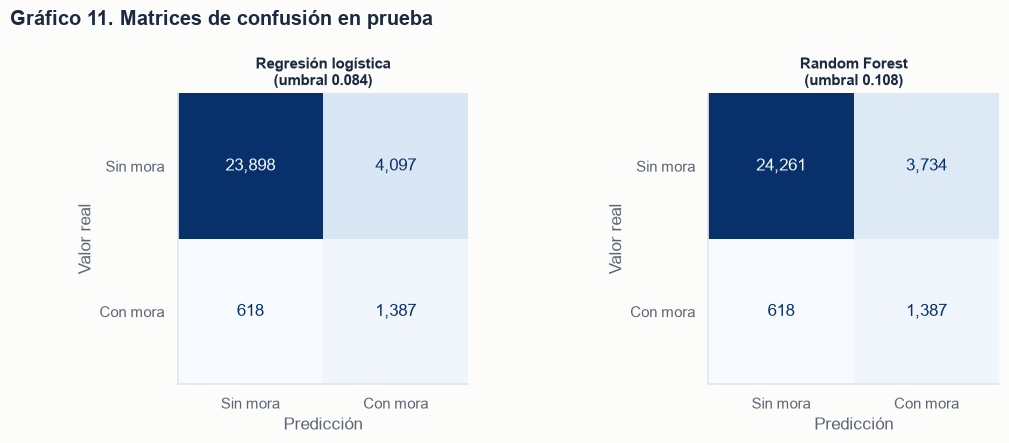

In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, nombre in zip(ejes, ["logistica", "random_forest"]):
    prediccion = (proba_test[nombre] >= umbrales[nombre]).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_test, prediccion, display_labels=["Sin mora", "Con mora"], cmap="Blues",
        colorbar=False, values_format=",", ax=ax)
    ax.set_title(f"{NOMBRES_MODELOS[nombre]}\n(umbral {umbrales[nombre]:.3f})", fontsize=11, loc="center")
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Valor real")
    ax.grid(False)
fig.suptitle("Gráfico 11. Matrices de confusión en prueba", x=0.01, ha="left",
             fontweight="bold", color=TINTA)
fig.tight_layout()
guardar_figura(fig, "11_matrices_confusion")
plt.show()

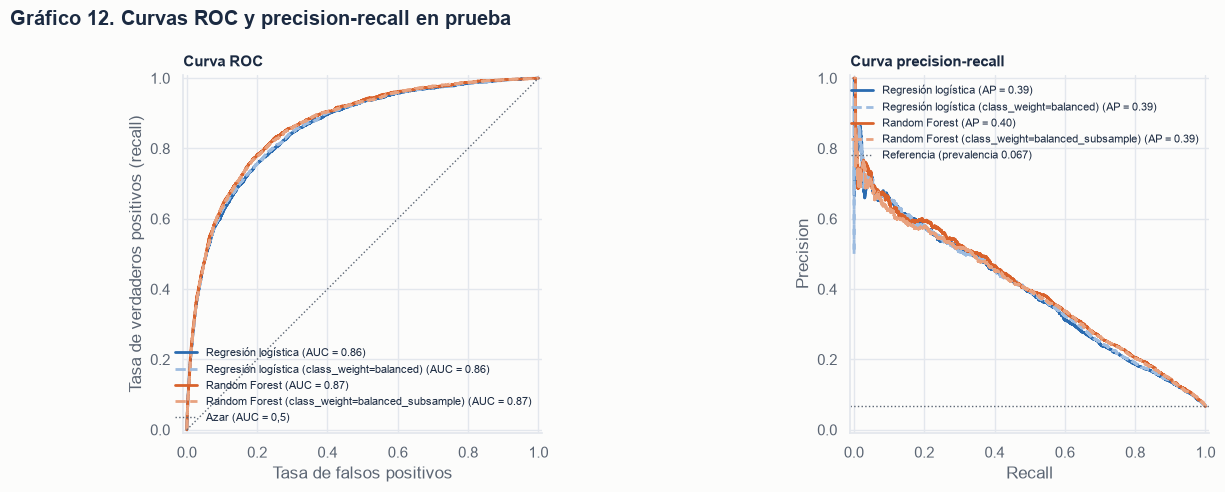

In [10]:
estilos = {"logistica": (AZUL, "-"), "logistica_balanceada": (AZUL_CLARO, "--"),
           "random_forest": (NARANJA, "-"), "random_forest_balanceado": ("#E8A27F", "--")}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for nombre, (color, linea) in estilos.items():
    estilo = {"color": color, "linestyle": linea, "linewidth": 2}
    RocCurveDisplay.from_predictions(y_test, proba_test[nombre], name=NOMBRES_MODELOS[nombre],
                                     curve_kwargs=estilo, ax=ax1)
    PrecisionRecallDisplay.from_predictions(y_test, proba_test[nombre], name=NOMBRES_MODELOS[nombre],
                                            curve_kwargs=estilo, ax=ax2)
ax1.plot([0, 1], [0, 1], color=TINTA_SECUNDARIA, linestyle=":", linewidth=1, label="Azar (AUC = 0,5)")
ax1.set_title("Curva ROC", fontsize=11)
ax1.set_xlabel("Tasa de falsos positivos")
ax1.set_ylabel("Tasa de verdaderos positivos (recall)")
ax1.legend(fontsize=8, loc="lower right")
ax2.axhline(y_test.mean(), color=TINTA_SECUNDARIA, linestyle=":", linewidth=1,
            label=f"Referencia (prevalencia {y_test.mean():.3f})")
ax2.set_title("Curva precision-recall", fontsize=11)
ax2.set_xlabel("Recall")
ax2.set_ylabel("Precision")
ax2.legend(fontsize=8, loc="upper right")
fig.suptitle("Gráfico 12. Curvas ROC y precision-recall en prueba", x=0.01, ha="left",
             fontweight="bold", color=TINTA)
fig.tight_layout()
guardar_figura(fig, "12_curvas_roc_pr")
plt.show()

**Interpretación.** Las curvas ROC de los cuatro modelos casi se superponen, con una ventaja pequeña y
consistente del Random Forest. La curva precision-recall es más exigente con el desbalance: incluso el
mejor modelo tiene una precision moderada cuando se busca un recall alto, porque los morosos son una
minoría y muchos perfiles de riesgo terminan pagando.

## 7. Calibración y niveles de riesgo

Cortes de nivel de riesgo: [0.0, 0.0668, 0.1077, 0.5, 1.0]


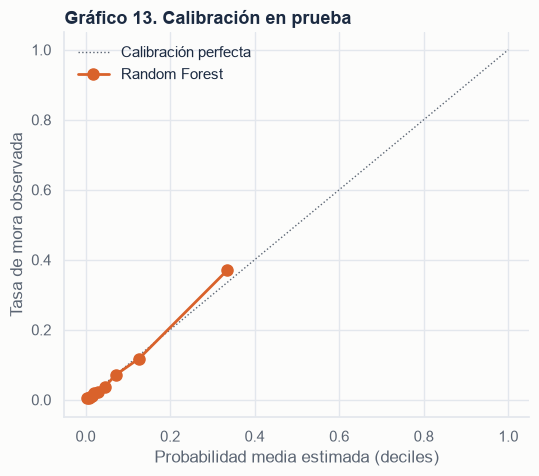

,clientes,probabilidad_media,tasa_mora_real,pct_clientes,pct_de_la_mora
nivel,,,,,
1. Bajo,22203,0.0214,0.0181,0.7401,0.2005
2. Medio,2676,0.0846,0.0807,0.0892,0.1077
3. Alto,4783,0.2319,0.2455,0.1594,0.5855
4. Muy alto,338,0.5662,0.6302,0.0113,0.1062


In [11]:
tasa_base = float(y_train.mean())
cortes_riesgo, etiquetas_riesgo = definir_niveles_riesgo(tasa_base, umbral)
print("Cortes de nivel de riesgo:", [round(c, 4) for c in cortes_riesgo[:-1]] + [1.0])

p_sel = proba_test[seleccionado]
frac_real, prob_media = calibration_curve(y_test, p_sel, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], color=TINTA_SECUNDARIA, linestyle=":", linewidth=1, label="Calibración perfecta")
ax.plot(prob_media, frac_real, color=NARANJA, marker="o", markersize=8, linewidth=2,
        label=NOMBRES_MODELOS[seleccionado])
ax.set_xlabel("Probabilidad media estimada (deciles)")
ax.set_ylabel("Tasa de mora observada")
ax.legend()
ax.set_title("Gráfico 13. Calibración en prueba")
guardar_figura(fig, "13_calibracion")
plt.show()

niveles = pd.DataFrame({"nivel": asignar_nivel_riesgo(p_sel, cortes_riesgo, etiquetas_riesgo),
                        "probabilidad": p_sel, "real": y_test.to_numpy()})
resumen_niveles = niveles.groupby("nivel").agg(
    clientes=("real", "size"), probabilidad_media=("probabilidad", "mean"), tasa_mora_real=("real", "mean"))
resumen_niveles["pct_clientes"] = resumen_niveles["clientes"] / len(niveles)
resumen_niveles["pct_de_la_mora"] = niveles.groupby("nivel")["real"].sum() / niveles["real"].sum()
resumen_niveles

**Interpretación.** Las probabilidades del Random Forest están bien calibradas: en cada decil la tasa de
mora observada es muy parecida a la probabilidad media estimada, por lo que pueden leerse como
estimaciones de riesgo y no solo como un ranking. Los niveles de riesgo ordenan correctamente a la cartera
de prueba:

| Nivel | Clientes | % cartera | Prob. media | Mora real | % de toda la mora |
|---|---|---|---|---|---|
| 1. Bajo | 22 203 | 74,0 % | 2,14 % | 1,81 % | 20,0 % |
| 2. Medio | 2 676 | 8,9 % | 8,46 % | 8,07 % | 10,8 % |
| 3. Alto | 4 783 | 15,9 % | 23,19 % | 24,55 % | 58,6 % |
| 4. Muy alto | 338 | 1,1 % | 56,62 % | 63,02 % | 10,6 % |

Los niveles Alto y Muy alto concentran el 17,1 % de los clientes y el 69,2 % de la mora observada.

## 8. Interpretabilidad

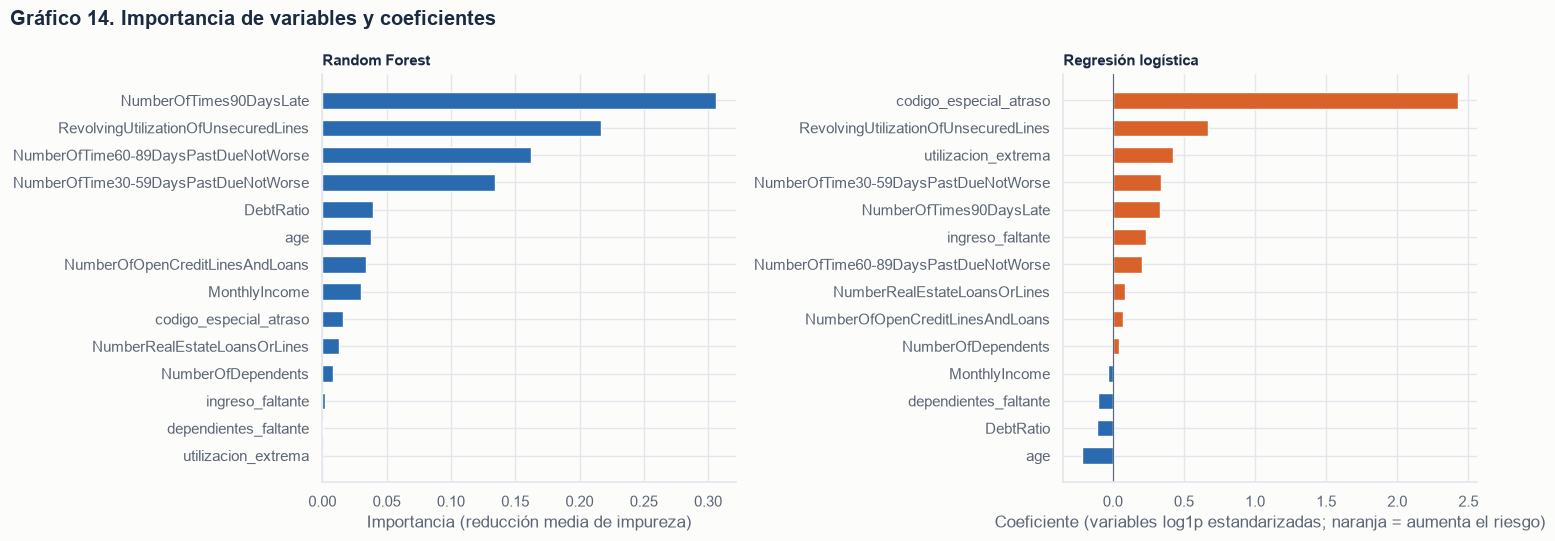

Coeficientes de la regresión logística (odds ratio por +1 desviación estándar):
                                      coeficiente  odds_ratio
codigo_especial_atraso                     2.4280     11.3410
RevolvingUtilizationOfUnsecuredLines       0.6720      1.9570
utilizacion_extrema                        0.4270      1.5320
NumberOfTime30-59DaysPastDueNotWorse       0.3400      1.4060
NumberOfTimes90DaysLate                    0.3330      1.3960
ingreso_faltante                           0.2320      1.2610
NumberOfTime60-89DaysPastDueNotWorse       0.2040      1.2260
NumberRealEstateLoansOrLines               0.0840      1.0880
NumberOfOpenCreditLinesAndLoans            0.0700      1.0730
NumberOfDependents                         0.0430      1.0440
MonthlyIncome                             -0.0320      0.9680
dependientes_faltante                     -0.1070      0.8990
DebtRatio                                 -0.1080      0.8980
age                                       -0.2160   

In [12]:
rf = modelos["random_forest"]
nombres = rf.named_steps["preprocesar"].get_feature_names_out()
importancia_rf = pd.Series(rf.named_steps["modelo"].feature_importances_, index=nombres).sort_values()

log = modelos["logistica"]
coeficientes = pd.Series(log.named_steps["modelo"].coef_[0],
                         index=log.named_steps["preprocesar"].get_feature_names_out()).sort_values()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))
ax1.barh(importancia_rf.index, importancia_rf.values, color=AZUL, height=0.6)
ax1.set_xlabel("Importancia (reducción media de impureza)")
ax1.set_title("Random Forest", fontsize=11)
ax2.barh(coeficientes.index, coeficientes.values,
         color=[NARANJA if v > 0 else AZUL for v in coeficientes.values], height=0.6)
ax2.axvline(0, color=TINTA_SECUNDARIA, linewidth=0.8)
ax2.set_xlabel("Coeficiente (variables log1p estandarizadas; naranja = aumenta el riesgo)")
ax2.set_title("Regresión logística", fontsize=11)
fig.suptitle("Gráfico 14. Importancia de variables y coeficientes", x=0.01, ha="left",
             fontweight="bold", color=TINTA)
fig.tight_layout()
guardar_figura(fig, "14_importancia_coeficientes")
plt.show()
print("Coeficientes de la regresión logística (odds ratio por +1 desviación estándar):")
print(pd.DataFrame({"coeficiente": coeficientes, "odds_ratio": np.exp(coeficientes)})
        .sort_values("coeficiente", ascending=False).round(3))

                                      Random Forest  Regresión logística
RevolvingUtilizationOfUnsecuredLines         0.0611               0.1033
NumberOfTime30-59DaysPastDueNotWorse         0.0337               0.0320
NumberOfTimes90DaysLate                      0.0333               0.0259
NumberOfTime60-89DaysPastDueNotWorse         0.0165               0.0098
age                                          0.0084               0.0082
NumberOfOpenCreditLinesAndLoans              0.0055               0.0022
DebtRatio                                    0.0049               0.0016
MonthlyIncome                                0.0015               0.0003
NumberRealEstateLoansOrLines                 0.0012               0.0012
ingreso_faltante                             0.0011               0.0017
codigo_especial_atraso                       0.0011               0.0021
NumberOfDependents                           0.0008               0.0002
dependientes_faltante                        0.0000

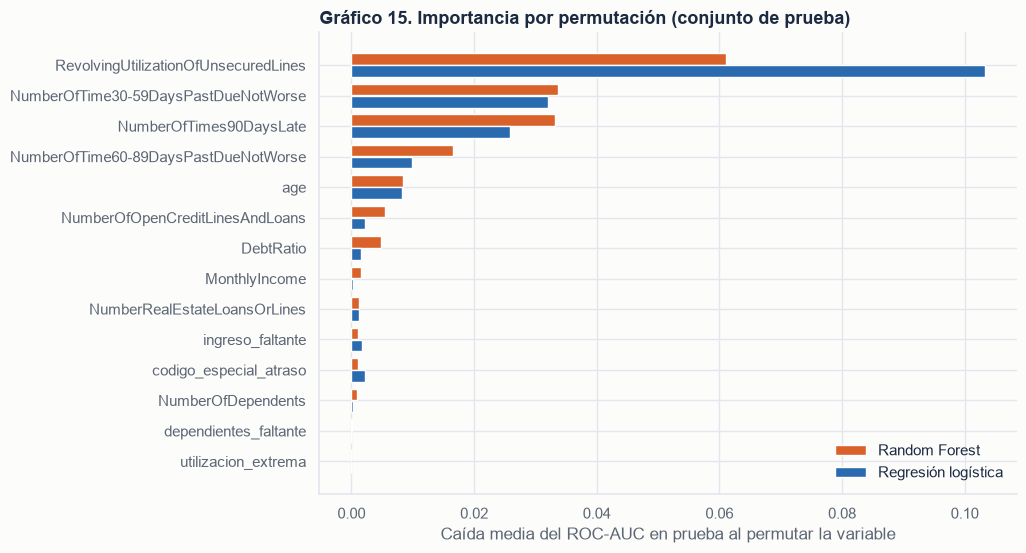

In [13]:
# Importancia por permutación en prueba: caída del ROC-AUC al desordenar cada variable
permutacion = {}
for nombre in ["random_forest", "logistica"]:
    resultado = permutation_importance(modelos[nombre], X_test, y_test, scoring="roc_auc",
                                       n_repeats=5, random_state=SEMILLA, n_jobs=-1)
    permutacion[NOMBRES_MODELOS[nombre]] = pd.Series(resultado.importances_mean, index=X_test.columns)
permutacion = pd.DataFrame(permutacion).sort_values("Random Forest")
print(permutacion.sort_values("Random Forest", ascending=False).round(4))

fig, ax = plt.subplots(figsize=(9, 6))
posiciones = np.arange(len(permutacion))
ax.barh(posiciones + 0.2, permutacion["Random Forest"], height=0.38, color=NARANJA, label="Random Forest")
ax.barh(posiciones - 0.2, permutacion["Regresión logística"], height=0.38, color=AZUL,
        label="Regresión logística")
ax.set_yticks(posiciones, permutacion.index)
ax.set_xlabel("Caída media del ROC-AUC en prueba al permutar la variable")
ax.legend(loc="lower right")
ax.set_title("Gráfico 15. Importancia por permutación (conjunto de prueba)")
guardar_figura(fig, "15_importancia_permutacion")
plt.show()

**Interpretación.** Los tres métodos coinciden en las variables con mayor asociación predictiva:

1. **Utilización del crédito rotativo**: es la variable cuya permutación más reduce el ROC-AUC en prueba
   (−0,061 en Random Forest, −0,103 en la logística). Más utilización, más riesgo.
2. **Atrasos previos** (30-59, 90+ y 60-89 días): la permutación de cada uno reduce el AUC entre 0,010 y
   0,034. En Random Forest, `NumberOfTimes90DaysLate` es la variable con mayor importancia por impureza.
3. **Edad**: asociación negativa (coeficiente −0,216; odds ratio 0,81 por desviación estándar) y una caída de
   AUC de ≈0,008.
4. Ingreso, ratio de deuda, dependientes y préstamos inmobiliarios aportan poco una vez considerados los
   atrasos y la utilización.

El coeficiente más alto de la logística es el de `codigo_especial_atraso` (odds ratio 11,3): estos clientes
tienen una mora del 54,7 %, pero son solo el 0,18 % de la cartera, por lo que su importancia por
permutación es baja. La importancia por impureza del Random Forest tiende a favorecer variables con muchos
valores distintos; por eso se contrasta con la importancia por permutación.

Estas importancias describen **asociaciones predictivas** aprendidas de datos históricos, no relaciones
causales: reducir artificialmente la utilización de un cliente no garantiza reducir su riesgo real.

## 9. Exportación de artefactos

In [14]:
predicciones = pd.DataFrame({
    "probabilidad_mora": p_sel,
    "prediccion_mora": (p_sel >= umbral).astype(int),
    "nivel_riesgo": asignar_nivel_riesgo(p_sel, cortes_riesgo, etiquetas_riesgo),
    OBJETIVO: y_test.to_numpy(),
}, index=X_test.index)

configuracion = guardar_artefactos(modelos[seleccionado], seleccionado, umbral, cortes_riesgo,
                                   etiquetas_riesgo, tasa_base, metricas_cv, metricas_test, predicciones)
comparacion.to_csv(RAIZ / "reports" / "comparacion_imputacion.csv", index=False)
tabla_test.to_csv(RAIZ / "reports" / "metricas_prueba.csv")
configuracion

{'modelo_seleccionado': 'random_forest',
 'descripcion_modelo': 'Random Forest',
 'umbral_clasificacion': 0.10772869452238389,
 'criterio_umbral': 'máximo F2 en predicciones out-of-fold del entrenamiento',
 'cortes_nivel_riesgo': [0.0,
  0.06684166666666666,
  0.10772869452238389,
  0.5,
  1.0],
 'etiquetas_nivel_riesgo': ['1. Bajo', '2. Medio', '3. Alto', '4. Muy alto'],
 'tasa_base_entrenamiento': 0.06684166666666666,
 'predictoras': ['RevolvingUtilizationOfUnsecuredLines',
  'age',
  'NumberOfTime30-59DaysPastDueNotWorse',
  'DebtRatio',
  'MonthlyIncome',
  'NumberOfOpenCreditLinesAndLoans',
  'NumberOfTimes90DaysLate',
  'NumberRealEstateLoansOrLines',
  'NumberOfTime60-89DaysPastDueNotWorse',
  'NumberOfDependents',
  'ingreso_faltante',
  'dependientes_faltante',
  'codigo_especial_atraso',
  'utilizacion_extrema'],
 'semilla': 42,
 'proporcion_prueba': 0.2,
 'n_pliegues_cv': 5,
 'version_scikit_learn': '1.9.1',
 'fecha_entrenamiento_utc': '2026-10-26T03:23:17+00:00'}

In [15]:
# Archivos para Power BI (cartera completa, predicciones de prueba y métricas)
generar_dashboard.main()

cartera.csv: 150000 filas
datos_dashboard.csv: 30000 filas (conjunto de prueba)
nivel_riesgo
1. Bajo        22203
2. Medio        2676
3. Alto         4783
4. Muy alto      338


Artefactos generados:

* `models/modelo_seleccionado.joblib`: pipeline completo (limpieza posterior + modelo); no se versiona en Git.
* `reports/configuracion_modelo.json`: modelo, umbral, cortes de riesgo, semilla y versión de scikit-learn.
* `reports/metricas.json` y `reports/metricas_prueba.csv`: métricas de validación cruzada y de prueba.
* `reports/predicciones_test.csv` y `dashboard/datos_dashboard.csv`: predicciones del conjunto de prueba.
* `reports/figuras/`: todos los gráficos.

Las etiquetas reales se conservan solo para evaluar el modelo sobre este histórico. Las probabilidades
son estimaciones, no certezas sobre el comportamiento futuro de un cliente.

## 10. Conclusiones

* **Modelo recomendado: Random Forest sin ponderación de clases** (300 árboles, `min_samples_leaf=50`). Tiene el
  mejor ROC-AUC en validación cruzada (0,8643) y en prueba (0,8680), la mejor *average precision* (0,4014),
  menos falsas alarmas que la logística con el mismo recall y probabilidades bien calibradas, lo que permite
  definir niveles de riesgo interpretables.
* **Umbral operativo 0,1077** (máximo F2 en validación cruzada): en prueba detecta el 69,2 % de los
  morosos con una precision del 27,1 %.
* La regresión logística es casi tan buena (ROC-AUC 0,859-0,861) y más fácil de explicar a un comité; es
  una alternativa válida si la transparencia regulatoria pesa más que 0,007 puntos de AUC.
* `class_weight` no mejoró la capacidad de ordenamiento: con un umbral bien elegido se obtiene el mismo
  compromiso sin distorsionar las probabilidades.

**Limitaciones.** Datos de 2011 sin fechas ni variables macroeconómicas; sin información de costes reales
por tipo de error; hiperparámetros no optimizados exhaustivamente; el modelo puede reproducir sesgos
históricos (p. ej. por edad), lo que exigiría un análisis de equidad antes de cualquier uso real. Resultados
con fines educativos: no constituyen una decisión crediticia.